# TP2 — Répondre par oui ou non : la classification binaire
**ÉNONCÉ** · Durée estimée : **une demi-journée**

## 🎯 Ce que vous allez apprendre
- Construire un réseau de **classification binaire** (sigmoïde, perte binary_crossentropy)
- Lire une **matrice de confusion** et calculer **précision** et **rappel** à la main
- Comprendre que **toutes les erreurs ne se valent pas** selon le contexte
- Déplacer le **seuil de décision** et mesurer le compromis, tracer la **courbe ROC**

## 🧰 Boîte à outils
Noms de fonctions et de classes utiles. **Aucun exemple d'appel n'est donné** : cherchez dans la documentation (scikit-learn, Keras, NumPy, matplotlib) comment les utiliser.

`load_breast_cancer`  ·  `train_test_split`  ·  `StandardScaler`  ·  `LogisticRegression`  ·  `keras.Sequential`  ·  `layers.Dense`  ·  `EarlyStopping`  ·  `model.predict`  ·  `np.sum`  ·  `confusion_matrix`  ·  `precision_score`  ·  `recall_score`  ·  `roc_auc_score`  ·  `roc_curve`

## 📘 Comment travailler
- Les cellules **déjà écrites** sont à lire et à exécuter.
- Les cellules **🎯 Étape** sont à **écrire vous-même**, à partir de la consigne.
- Après chaque étape, une cellule **✅ Contrôle** vérifie votre résultat. Respectez les **noms de variables** demandés.
- Les questions **✍️** demandent une réponse écrite : c'est là que vous montrez que vous avez compris.
- Bloqué ? Relisez l'indice, puis cherchez dans la documentation. Un message d'erreur se lit : la dernière ligne dit souvent ce qui ne va pas.

In [27]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, confusion_matrix, precision_score, recall_score
from tensorflow import keras
from tensorflow.keras import layers, regularizers
keras.utils.set_random_seed(42)

def controle(condition, ok, ko):
    print("✅", ok) if condition else print("❌", ko)

## Étape 1 — Les données : détecter des tumeurs malignes
569 tumeurs, **30 mesures** par tumeur (taille, texture, forme des cellules…). On veut prédire si la tumeur est **maligne (1)** ou bénigne (0). Dans ce jeu, scikit-learn code l'inverse (0 = malin) : on le retourne pour que **1 = la chose à détecter**.

In [28]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()
X = data.data
y = 1 - data.target          # 1 = tumeur maligne
print(X.shape, "| part de tumeurs malignes :", round(y.mean(), 3))
pd.DataFrame(X[:, :5], columns=data.feature_names[:5]).head()

(569, 30) | part de tumeurs malignes : 0.373


,mean radius,mean texture,mean perimeter,mean area,mean smoothness
0,17.99,10.38,122.80,1001.0,0.11840
1,20.57,17.77,132.90,1326.0,0.08474
2,19.69,21.25,130.00,1203.0,0.10960
3,11.42,20.38,77.58,386.1,0.14250
4,20.29,14.34,135.10,1297.0,0.10030


## 🎯 Étape 2 — Découper et mettre à l'échelle
Les 30 colonnes ont des ordres de grandeur très différents (une aire vaut des centaines, une finesse vaut 0,1). On les **standardise**. ⚠️ La moyenne et l'écart-type se calculent sur l'**apprentissage seul**, sinon le test « souffle » des informations au modèle : c'est une **fuite de données**.

**À faire :** Découpez en `X_train`, `X_test`, `y_train`, `y_test` : **20 % de test**, **stratifié sur `y`** (mêmes proportions de malins dans les deux jeux), `random_state=42`. Puis standardisez `X_train` et `X_test` (fit sur le train seulement).

> 💡 **Indice** : `train_test_split(..., stratify=...)`. `StandardScaler` : `fit_transform` sur le train, `transform` sur le test.

In [ ]:
# TODO : découper (stratifié), puis standardiser
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f"Taille du X_train : {X_train.shape} | Taille du X_test : {X_test.shape}")

Taille du X_train : (455, 30) | Taille du X_test  : (114, 30)


In [13]:
# ✅ Contrôle (ne pas modifier)
controle(X_train.shape == (455, 30) and X_test.shape == (114, 30) and abs(X_train.mean()) < 1e-6, 'Découpage et échelle corrects', 'Attendu (455, 30) et (114, 30), train de moyenne 0')

✅ Découpage et échelle corrects


## 🎯 Étape 3 — Les références à battre
Si **90 % des cas sont bénins**, répondre toujours « bénin » donne 90 % de bonnes réponses sans rien comprendre. On regarde donc deux références.

**À faire :** Calculez `acc_betise` (part de bonnes réponses en répondant **toujours la classe la plus fréquente du train**) et `acc_logistique` (précision d'une **régression logistique** sur le test).

> 💡 **Indice** : La classe la plus fréquente : `y_train.mean()`. `LogisticRegression(max_iter=2000)` puis `.score(X_test, y_test)`.

In [30]:
from sklearn.linear_model import LogisticRegression
# TODO : acc_betise et acc_logistique

# Calcul de la classe majoritaire
classe_majoritaire = 1 if y_train.mean() > 0.5 else 0

# Calcul de l'accuracy de la classe majoritaire
acc_betise = np.mean(y_train == classe_majoritaire)

# Calcul de l'accuracy de la régression logistique
acc_logistique = LogisticRegression(max_iter=2000, random_state=42).fit(X_train,y_train).score(X_test,y_test)

print(f"Betise : {acc_betise:.2%} ; Logistique : {acc_logistique:.2%}")

Betise : 62.64% ; Logistique : 96.49%


In [19]:
# ✅ Contrôle (ne pas modifier)
controle(0.55 < acc_betise < 0.7 and acc_logistique > 0.93, 'Références plausibles', 'Attendu : « toujours pareil » ≈ 0.6 et régression logistique > 0.93')

✅ Références plausibles


## 🎯 Étape 4 — Construire le réseau
Pour une réponse **oui / non**, la sortie est **un neurone avec une sigmoïde** (une probabilité entre 0 et 1) et la perte est la **binary_crossentropy**, qui punit surtout les réponses **sûres et fausses**.

**À faire :** Construisez `modele` : entrée de 30, une couche de **16 neurones (ReLU)**, une de **8 (ReLU)**, une sortie de 1 neurone **sigmoïde**. Compilez avec **adam**, **binary_crossentropy** et la métrique **accuracy**.

> 💡 **Indice** : Même squelette qu'au TP1. Seuls la **sortie** et la **perte** changent.

In [31]:
keras.utils.set_random_seed(42)
# TODO : construire et compiler modele

modele = keras.Sequential([
    layers.Input(shape=(30,)),
    layers.Dense(16, activation='relu'),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid'),
])
modele.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [21]:
# ✅ Contrôle (ne pas modifier)
controle(modele.count_params() == 641, 'Réseau correct : 641 paramètres', 'Attendu 641 paramètres, obtenu ' + str(modele.count_params()))

✅ Réseau correct : 641 paramètres


## 🎯 Étape 5 — Entraîner avec arrêt précoce
Plutôt que de deviner le bon nombre d'epochs, on laisse le réseau s'arrêter **quand la perte de validation cesse de s'améliorer** (`EarlyStopping`), et on **reprend les meilleurs poids**.

**À faire :** Entraînez `modele` : **100 epochs maximum**, batch de 16, 20 % de validation, avec un arrêt précoce de **patience 10** qui restaure les meilleurs poids. Stockez le résultat dans `histoire`.

> 💡 **Indice** : `keras.callbacks.EarlyStopping(monitor=..., patience=..., restore_best_weights=...)`, passé via l'argument `callbacks`.

In [ ]:
# Configuration de l'arret précoce
early_stopping = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Entraînement du modèle avec l'arrêt précoce (Epoque 100, Batch 16, Validation 20%)
histoire = modele.fit(X_train, y_train, epochs=100, batch_size=16, validation_split=0.2, callbacks=[early_stopping])

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - accuracy: 0.6429 - loss: 0.6384 - val_accuracy: 0.8132 - val_loss: 0.5000
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8297 - loss: 0.4794 - val_accuracy: 0.8791 - val_loss: 0.3880
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9093 - loss: 0.3767 - val_accuracy: 0.9231 - val_loss: 0.3081
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9478 - loss: 0.2959 - val_accuracy: 0.9231 - val_loss: 0.2512
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9560 - loss: 0.2361 - val_accuracy: 0.9451 - val_loss: 0.2110
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9615 - loss: 0.1920 - val_accuracy: 0.9451 - val_loss: 0.1817
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9698 - loss: 0.1587 - val_accuracy: 0.9451 - val_loss: 0.1619
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9780 - loss: 0.1350 - val_accuracy: 0.945

In [33]:
# ✅ Contrôle (ne pas modifier)
controle(len(histoire.history['loss']) < 100, 'Arrêt automatique avant 100 epochs (%d)' % len(histoire.history['loss']), 'Le réseau est allé jusqu\'à 100 epochs : l\'arrêt précoce n\'a pas joué')

✅ Arrêt automatique avant 100 epochs (84)


## Étape 6 — Les courbes
Perte et précision, sur l'apprentissage (bleu) et la validation (orange).

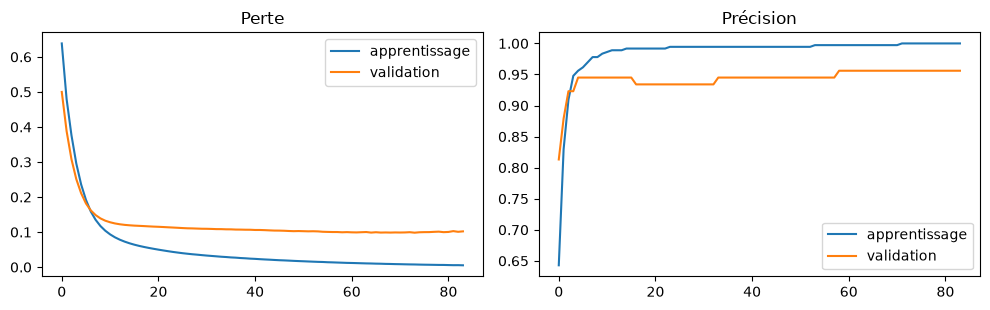

In [34]:
h = histoire.history
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(h["loss"], label="apprentissage"); ax[0].plot(h["val_loss"], label="validation"); ax[0].set_title("Perte"); ax[0].legend()
ax[1].plot(h["accuracy"], label="apprentissage"); ax[1].plot(h["val_accuracy"], label="validation"); ax[1].set_title("Précision"); ax[1].legend()
plt.tight_layout(); plt.show()

## 🎯 Étape 7 — La matrice de confusion, calculée à la main
Au lieu d'un seul pourcentage, on **compte les quatre cas** : **VP** (malin détecté), **VN** (bénin reconnu), **FP** (fausse alerte : bénin annoncé malin), **FN** (tumeur maligne **ratée**).

- **Précision** = `VP / (VP + FP)` : « quand le modèle crie au malin, a-t-il raison ? »
- **Rappel** = `VP / (VP + FN)` : « parmi les vraies tumeurs malignes, combien a-t-on trouvées ? »

**À faire :** Calculez `proba` (probabilités prédites sur `X_test`, à plat) puis `pred` (classe prédite au **seuil 0,5**). Comptez `VP`, `VN`, `FP`, `FN` avec NumPy (sans bibliothèque de métriques), puis `precision` et `rappel`.

> 💡 **Indice** : `np.sum((pred == 1) & (y_test == 1))` compte les VP. Faites de même pour les trois autres cas.

In [59]:
    # TODO : proba, pred, VP, VN, FP, FN, precision, rappel
proba = modele.predict(X_test).ravel()
pred = (proba > 0.5).astype(int)

# 1 pour Malin, 0 pour Bénin
VP = np.sum((pred == 1) & (y_test == 1))
VN = np.sum((pred == 0) & (y_test == 0))
FP = np.sum((pred == 1) & (y_test == 0))
FN = np.sum((pred == 0) & (y_test == 1))

precision = VP / (VP + FP)
rappel = VP / (VP + FN)

print(f"Précision : {precision:.2%} | Rappel : {rappel:.2%}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
Précision : 100.00% | Rappel : 92.86%


In [46]:
# ✅ Contrôle (ne pas modifier)
controle(VP + VN + FP + FN == 114 and abs(precision - precision_score(y_test, pred)) < 1e-9 and abs(rappel - recall_score(y_test, pred)) < 1e-9, 'Vos comptes retrouvent ceux de scikit-learn', 'Vos nombres ne correspondent pas à precision_score / recall_score')

✅ Vos comptes retrouvent ceux de scikit-learn


### ✍️ Question
**Dans ce contexte médical, quelle erreur est la plus grave : le faux positif ou le faux négatif ? Que disent vos chiffres ?**

*Votre réponse (2 à 4 lignes) :*

> Quand le modèle prédit une tumeur maligne il a toujours raison, il n'y a donc pas de faux positif. Cependant le taux de detection reste relativement faible (~93%), ce qui provoque de faux négatif; d'un point de vue purement médical, il est plus grave de ne pas détecter une tumeur que de détecter une tumeur qui n'existe pas.

## 🎯 Étape 8 — Déplacer le seuil
Le seuil 0,5 est un **choix par défaut**, pas une vérité. **Baisser** le seuil : le modèle crie plus facilement au malin (moins de tumeurs ratées, plus de fausses alertes).

**À faire :** Pour les seuils **0,5 / 0,3 / 0,1 / 0,05**, calculez la **précision**, le **rappel** et le **nombre de tumeurs malignes ratées (FN)**. Rangez le tout dans un tableau pandas `tableau` (une ligne par seuil).

> 💡 **Indice** : Une boucle sur les seuils, `pred = (proba > seuil)`, puis `pd.DataFrame(liste_de_dictionnaires)`.

In [ ]:
# TODO : construire le tableau pour les 4 seuils

proba = modele.predict(X_test).ravel()

resultats = []  # Liste pour stocker les résultats

for seuil in [0.5, 0.3, 0.1, 0.05]:
    pred = (proba > seuil).astype(int)
    precision = precision_score(y_test, pred) # Calcul de la précision
    rappel = recall_score(y_test, pred) # Calcul du rappel (précision réelle)
    nb_maligne_rate = np.sum((pred == 0) & (y_test == 1)) # Calcul du nombre de tumeurs malignes ratées
    resultats.append({'seuil': seuil, 'precision': precision, 'rappel': rappel, 'tumeurs ratées (FN)': nb_maligne_rate})

tableau = pd.DataFrame(resultats)  # Création du DataFrame à la fin

display(tableau)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


,seuil,precision,rappel,tumeurs ratées (FN)
0,0.50,1.000000,0.928571,3
1,0.30,1.000000,0.952381,2
2,0.10,0.953488,0.976190,1
3,0.05,0.931818,0.976190,1


In [68]:
# ✅ Contrôle (ne pas modifier)
controle(tableau['rappel'].is_monotonic_increasing and tableau['tumeurs ratées (FN)'].is_monotonic_decreasing, 'Plus le seuil baisse, plus le rappel monte', 'Attendu : le rappel augmente et les FN diminuent quand le seuil baisse')

✅ Plus le seuil baisse, plus le rappel monte


### ✍️ Question
**Quel seuil choisiriez-vous pour un dépistage ? Que payez-vous en échange ?**

*Votre réponse (2 à 4 lignes) :*

> Le meilleur compromis semble etre un seuil a 0.1, il a le meilleur taux de rappel et le moins de faux negatifs (1 seul). Cependant, il a une precision de 0.95, ce qui veut dire qu'on a 5% de Faux positifs. Cela peut etre un bon compromis pour un depistage. 

## 🎯 Étape 9 — La courbe ROC
Au lieu de choisir un seuil, la **courbe ROC** les montre **tous** : en abscisse le taux de fausses alertes, en ordonnée le rappel. L'**AUC** (aire sous la courbe) résume la capacité à séparer les deux classes : **0,5 = hasard, 1 = parfait**.

**À faire :** Calculez `auc` avec `proba` et tracez la courbe ROC (avec la diagonale du hasard).

> 💡 **Indice** : `roc_curve` renvoie trois tableaux ; `roc_auc_score` renvoie un nombre.

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve
# TODO : auc et courbe ROC
auc = roc_auc_score(y_test, proba)


0.9923941798941799

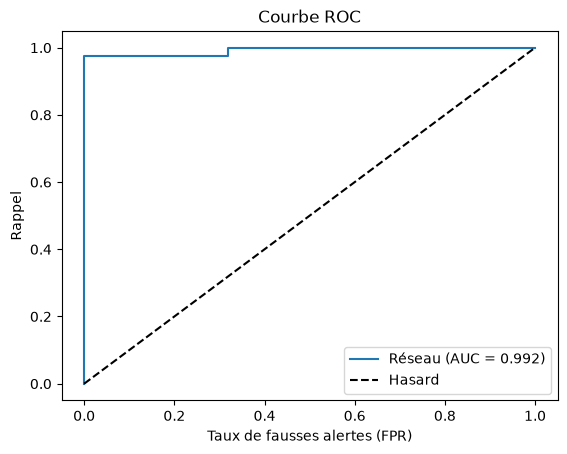

In [72]:
# Courbe ROC

fpr, rappel_roc, seuils = roc_curve(y_test, proba)     # 3 tableaux : FPR, TPR (= rappel), seuils

plt.plot(fpr, rappel_roc, label=f"Réseau (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Hasard")  # diagonale du hasard
plt.xlabel("Taux de fausses alertes (FPR)")
plt.ylabel("Rappel")
plt.title("Courbe ROC")
plt.legend()
plt.show()

In [71]:
# ✅ Contrôle (ne pas modifier)
controle(auc > 0.95, 'AUC = %.3f' % auc, 'Attendu une AUC supérieure à 0.95')

✅ AUC = 0.992


## ✅ Ce qu'il faut retenir
- **Classification binaire** : sortie sigmoïde, perte **binary_crossentropy**.
- **Matrice de confusion** : VP, VN, FP, FN. **Précision** = « quand j'annonce, ai-je raison ? », **rappel** = « combien en ai-je retrouvé ? ».
- **Toutes les erreurs ne se valent pas** : le contexte décide laquelle est la plus grave.
- Le **seuil** règle le compromis précision / rappel ; la **courbe ROC / AUC** résume tous les seuils.
- **Standardiser avec les statistiques de l'apprentissage seul**, toujours.